# 01 — Exploratory Data Analysis (EDA)
**Project:** Fake News Detection Using Natural Language Processing

This notebook explores the raw datasets (`dataset/Fake.csv` and `dataset/True.csv`), examining:
1. Dataset shapes and column schemas
2. Missing value analysis
3. Duplicate article analysis
4. Class distribution (`FAKE = 0` vs. `REAL = 1`)
5. Subject category distribution
6. Article and headline length distributions with `matplotlib` and `seaborn` visualizations

## 1. Import Libraries

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)

## 2. Load `Fake.csv` and `True.csv`

In [2]:
DATASET_DIR = Path("../dataset")
FAKE_PATH = DATASET_DIR / "Fake.csv"
TRUE_PATH = DATASET_DIR / "True.csv"

if not FAKE_PATH.is_file() or not TRUE_PATH.is_file():
    raise FileNotFoundError(
        "Please place Fake.csv and True.csv inside the 'dataset/' folder before running this notebook."
    )

fake_df = pd.read_csv(FAKE_PATH)
true_df = pd.read_csv(TRUE_PATH)

fake_df["label"] = 0  # 0 = FAKE
true_df["label"] = 1  # 1 = REAL
fake_df["class_name"] = "FAKE"
true_df["class_name"] = "REAL"

print("Datasets loaded successfully!")

Datasets loaded successfully!


## 3. Display Shapes & Columns

In [3]:
print(f"Fake.csv shape : {fake_df.shape}")
print(f"True.csv shape : {true_df.shape}")
print(f"Fake.csv columns: {list(fake_df.columns)}")
print(f"True.csv columns: {list(true_df.columns)}")

df = pd.concat([fake_df, true_df], axis=0, ignore_index=True)
print(f"\nCombined dataset shape: {df.shape}")
df.head()

Fake.csv shape : (23481, 6)
True.csv shape : (21417, 6)
Fake.csv columns: ['title', 'text', 'subject', 'date', 'label', 'class_name']
True.csv columns: ['title', 'text', 'subject', 'date', 'label', 'class_name']

Combined dataset shape: (44898, 6)


,title,text,subject,date,label,class_name
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0,FAKE
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0,FAKE
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0,FAKE
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0,FAKE
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0,FAKE


## 4. Missing Value Analysis

In [4]:
missing_counts = df.isnull().sum()
empty_strings = (df[["title", "text"]].fillna("").apply(lambda col: col.astype(str).str.strip() == "")).sum()

print("Null / NaN counts per column:")
print(missing_counts)
print("\nBlank/whitespace-only counts in title & text:")
print(empty_strings)

Null / NaN counts per column:
title         0
text          0
subject       0
date          0
label         0
class_name    0
dtype: int64

Blank/whitespace-only counts in title & text:
title      0
text     631
dtype: int64


## 5. Duplicate Analysis

In [5]:
exact_dups = df.duplicated().sum()
title_text_dups = df.duplicated(subset=["title", "text"]).sum()

print(f"Exact duplicate rows: {exact_dups:,}")
print(f"Duplicate (title, text) pairs: {title_text_dups:,}")
print(f"Unique articles remaining after deduplication: {len(df) - title_text_dups:,}")

Exact duplicate rows: 209
Duplicate (title, text) pairs: 5,793
Unique articles remaining after deduplication: 39,105


## 6. Class Distribution (FAKE vs. REAL)

class_name
FAKE    23481
REAL    21417
Name: count, dtype: int64


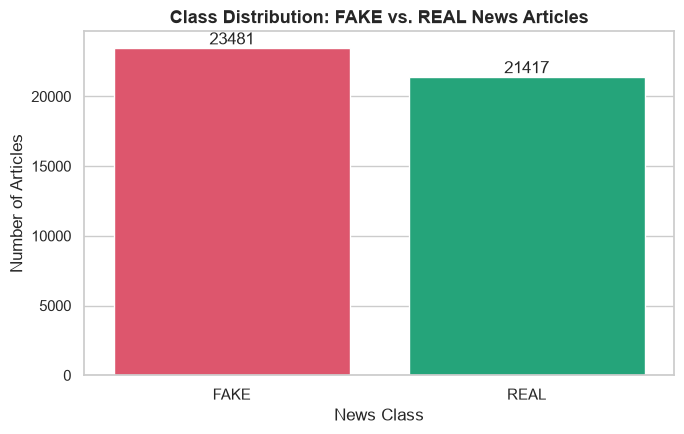

In [7]:
class_counts = df["class_name"].value_counts()
print(class_counts)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.countplot(data=df, x="class_name", hue="class_name", palette={"FAKE": "#f43f5e", "REAL": "#10b981"}, legend=False, ax=ax)
ax.set_title("Class Distribution: FAKE vs. REAL News Articles", fontsize=13, fontweight="bold")
ax.set_xlabel("News Class")
ax.set_ylabel("Number of Articles")
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
plt.tight_layout()
plt.show()

## 7. Subject Distribution

class_name  subject        
FAKE        Government News     1570
            Middle-east          778
            News                9050
            US_News              783
            left-news           4459
            politics            6841
REAL        politicsNews       11272
            worldnews          10145
dtype: int64


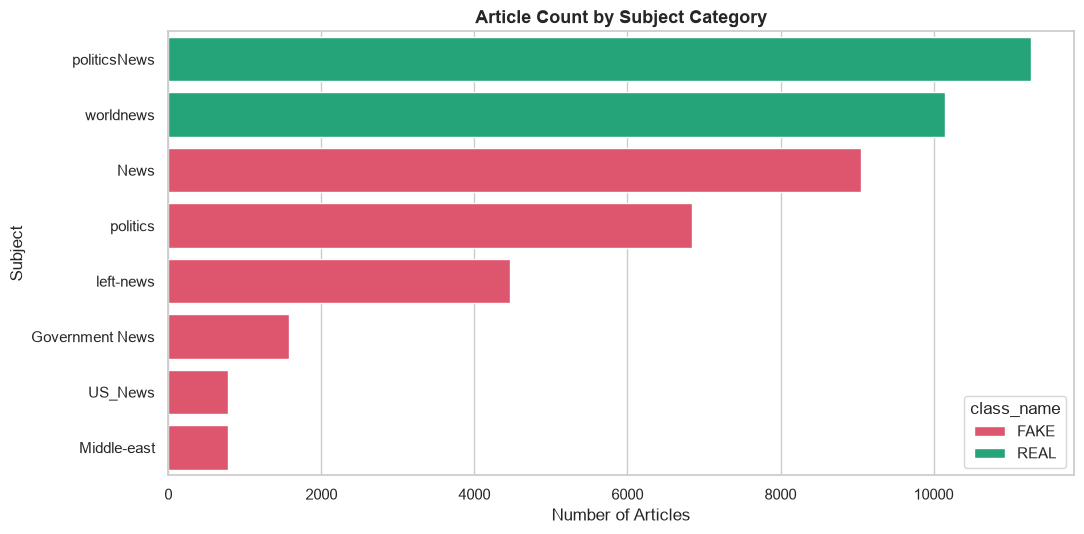

In [8]:
if "subject" in df.columns:
    print(df.groupby(["class_name", "subject"]).size())
    fig, ax = plt.subplots(figsize=(11, 5.5))
    sns.countplot(
        data=df,
        y="subject",
        hue="class_name",
        order=df["subject"].value_counts().index,
        palette={"FAKE": "#f43f5e", "REAL": "#10b981"},
        ax=ax,
    )
    ax.set_title("Article Count by Subject Category", fontsize=13, fontweight="bold")
    ax.set_xlabel("Number of Articles")
    ax.set_ylabel("Subject")
    plt.tight_layout()
    plt.show()
else:
    print("Column 'subject' not present in dataset.")

## 8. Article Length Analysis

Summary Statistics for Article Word Count by Class:


title_word_count                                                    \
                      count       mean       std  min   25%   50%   75%   max   
class_name                                                                      
FAKE                23481.0  14.732805  4.335099  1.0  12.0  14.0  17.0  42.0   
REAL                21417.0   9.954475  1.700747  4.0   9.0  10.0  11.0  20.0   

           text_word_count                                                    \
                     count        mean         std  min    25%    50%    75%   
class_name                                                                     
FAKE               23481.0  423.197905  408.388890  0.0  240.0  363.0  506.0   
REAL               21417.0  385.640099  274.006204  0.0  148.0  359.0  525.0   

                    
               max  
class_name          
FAKE        8135.0  
REAL        5172.0

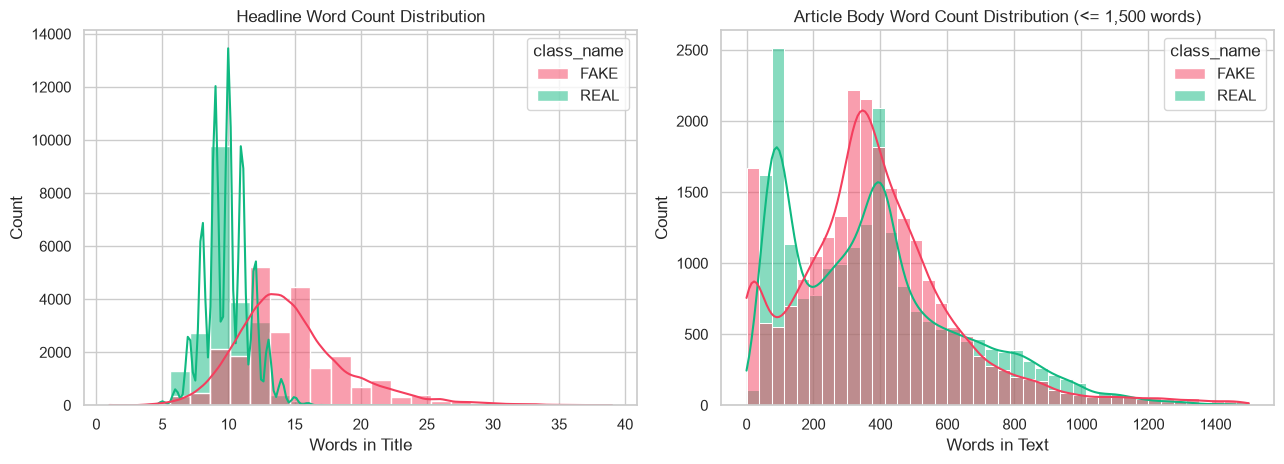

In [11]:
df["title_word_count"] = df["title"].fillna("").astype(str).apply(lambda s: len(s.split()))
df["text_word_count"] = df["text"].fillna("").astype(str).apply(lambda s: len(s.split()))

print("Summary Statistics for Article Word Count by Class:")
display(df.groupby("class_name")[["title_word_count", "text_word_count"]].describe())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.histplot(
    data=df[df["title_word_count"] <= 40],
    x="title_word_count",
    hue="class_name",
    bins=25,
    kde=True,
    palette={"FAKE": "#f43f5e", "REAL": "#10b981"},
    ax=axes[0],
)
axes[0].set_title("Headline Word Count Distribution")
axes[0].set_xlabel("Words in Title")

sns.histplot(
    data=df[df["text_word_count"] <= 1500],
    x="text_word_count",
    hue="class_name",
    bins=40,
    kde=True,
    palette={"FAKE": "#f43f5e", "REAL": "#10b981"},
    ax=axes[1],
)
axes[1].set_title("Article Body Word Count Distribution (<= 1,500 words)")
axes[1].set_xlabel("Words in Text")

plt.tight_layout()
plt.show()